In [54]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import colormaps as mpl_cmaps  
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.ticker import MultipleLocator, FormatStrFormatter
from matplotlib.colors import TwoSlopeNorm

# 1. Warm up (~5 min)
- Brief recap: 
    - Fundamentals of traffic flow theory
    - Sensing technologies
- Groups members: 

# 1. Data exploration (~10 min)

In [2]:
DATA_DIR = Path("/Users/cielyao/Library/CloudStorage/OneDrive-DelftUniversityofTechnology/Documents/TUDelft/POSTDOC/TA/dataset/")
PATTERN  = "* - A4L - km. 1.1-47 - uitvoer.txt"   # adjust if needed (e.g., km. 1-47)

# list files (rglob handles subfolders)
files = sorted(DATA_DIR.rglob(PATTERN))
rows  = []
for f in files:
    m = re.search(r"\d{4}-\d{2}-\d{2}", f.name)
    if m:
        rows.append({"date": m.group(0), "path": f})

day_table = (pd.DataFrame(rows).sort_values("date").reset_index(drop=True))
if day_table.empty:
    raise FileNotFoundError(f"No files matched in\n  {DATA_DIR}\npattern: {PATTERN}")

day_table.index.name = "DAY"
print("Available days (pick a number for DAY):")
print(day_table[["date"]])

Available days (pick a number for DAY):
           date
DAY            
0    2024-06-24
1    2024-06-25
2    2024-06-26
3    2024-06-27
4    2024-06-28
5    2025-06-16
6    2025-06-17
7    2025-06-18
8    2025-06-19
9    2025-06-20
10   2025-06-23
11   2025-06-24
12   2025-06-25
13   2025-06-26


In [3]:
# chosse your day here:
DAY = 3 

FILE = day_table.loc[DAY, "path"]
print(f"\nSelected [{DAY}] {day_table.loc[DAY,'date']}  ->  {FILE.name}")

def _date_from_filename(p: Path) -> str:
    return re.search(r"\d{4}-\d{2}-\d{2}", p.name).group(0)

def _attach_date(times: pd.Series, path: Path) -> pd.Series:
    """prepend file date to HH:MM and parse to Timestamp"""
    d = _date_from_filename(path)
    return pd.to_datetime(times.astype(str).radd(d + " "))

def tidy(wide: pd.DataFrame, value_name: str) -> pd.DataFrame:
    return (wide.melt(id_vars="time", var_name="km", value_name=value_name)
                .assign(km=lambda d: d["km"].str.replace("km_","",regex=False).astype(float))
                .sort_values(["time","km"]).reset_index(drop=True))

def parse_matrix(path: Path, title_pat: str, na_sentinel=-1.0) -> pd.DataFrame:
    """For 'Gebruikte intensiteiten' (veh/h) and 'Gebruikte snelheden' (km/h)."""
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    s = next(i for i,l in enumerate(lines) if re.search(title_pat, l, re.I))
    d = next(i for i in range(s+1, s+10) if re.match(r"\s*-{3,}\s*$", lines[i]))
    h = next(i for i in range(d+1, d+6) if re.search(r"\d+\.\d{3}", lines[i]))

    kms  = re.findall(r"\d+\.\d{3}", lines[h])
    cols = ["time"] + [f"km_{k}" for k in kms]

    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        vals = [float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", m.group(2))]
        vals = (vals + [np.nan]*len(kms))[:len(kms)]
        vals = [np.nan if v == na_sentinel else v for v in vals]
        rows.append([m.group(1)] + vals)

    df = pd.DataFrame(rows, columns=cols)
    df["time"] = _attach_date(df["time"], path)
    return df

def parse_travel_times(path: Path) -> pd.DataFrame:
    """'Berekende reistijden' (handles gap NaNs between avg/sd blocks)."""
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    s  = next(i for i,l in enumerate(lines) if re.search(r"Berekende reistijden", l, re.I))
    h  = next(i for i in range(s, s+15) if re.search(r"\bMethode\b", lines[i], re.I))

    hdr   = re.findall(r"(?:Ref\.)|\d+", lines[h])                # e.g. ['Ref.', '1','2','3','Ref.','1','2','3']
    pivot = hdr.index("Ref.", 1) if hdr.count("Ref.")>=2 else len(hdr)//2
    avg_names = [("ref_avg" if t=="Ref." else f"m{t}_avg") for t in hdr[:pivot]]
    sd_names  = [("ref_sd"  if t=="Ref." else f"m{t}_sd")  for t in hdr[pivot:]]

    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        toks = re.findall(r"(?:NaN|-?\d+(?:\.\d+)?)", m.group(2))
        nums = [np.nan if t.lower()=="nan" else float(t) for t in toks]
        avgs = (nums[:len(avg_names)] + [np.nan]*len(avg_names))[:len(avg_names)]
        rest = nums[len(avg_names):]
        while len(rest) > len(sd_names) and pd.isna(rest[0]):   # drop gap NaNs
            rest = rest[1:]
        sds  = (rest[:len(sd_names)] + [np.nan]*len(sd_names))[:len(sd_names)]
        rows.append([m.group(1)] + avgs + sds)

    df = pd.DataFrame(rows, columns=["time"] + avg_names + sd_names)
    df["time"] = _attach_date(df["time"], path)
    return df

def parse_network_indicators(path: Path) -> pd.DataFrame:
    """
    Parse the section 'Netwerk indicatoren per periode en per wegnummer'
    Columns shown in the file (example):
        A4-TDT (vrt.km), A4-TTS (vrt.uren), A4-TD (vrt.uren), A4-FZ (km.min), A4-NS (km/h)
    Returns a wide df with:
        time, a4_tdt, a4_tts, a4_td, a4_fz, a4_ns
    """
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    s = next(i for i, ln in enumerate(lines) if re.search(r"Netwerk indicatoren", ln, flags=re.I))
    d = next(i for i in range(s+1, min(s+10, len(lines))) if re.match(r"\s*-{3,}\s*$", lines[i]))
    h = next(i for i in range(d+1, min(d+6, len(lines))) if re.search(r"A4-", lines[i]))

    hdr_tokens = re.findall(r"(A4-[A-Za-z]+)", lines[h])
    short = {"A4-TDT":"a4_tdt", "A4-TTS":"a4_tts", "A4-TD":"a4_td", "A4-FZ":"a4_fz", "A4-NS":"a4_ns"}
    col_names = ["time"] + [short.get(tok, tok.lower().replace("-", "_")) for tok in hdr_tokens]
    n_expected = len(col_names) - 1

    rows = []
    for ln in lines[h+1:]:
        m = re.match(r"^(\d{2}:\d{2})\s+(.*)$", ln.strip())
        if not m:
            if rows: break
            else:    continue
        nums = re.findall(r"-?\d+(?:\.\d+)?", m.group(2))
        vals = [float(x) for x in nums]
        vals = (vals + [np.nan]*n_expected)[:n_expected]
        vals = [np.nan if v == -1.0 else v for v in vals]
        rows.append([m.group(1)] + vals)
    df = pd.DataFrame(rows, columns=col_names)
    df["time"] = _attach_date(df["time"], path)
    return df


Selected [3] 2024-06-27  ->  2024-06-27 - A4L - km. 1.1-47 - uitvoer.txt


In [ ]:
# Load data 
# Inspect dataset structure (variables, time span, sensors, incidents).
# Perform basic statistics (mean speeds, flows, lane utilization).
flow_w  = parse_matrix(FILE, r"Gebruikte intensiteiten")  # veh/h
speed_w = parse_matrix(FILE, r"Gebruikte snelheden")      # km/h
tt_w    = parse_travel_times(FILE)                        # sec (Ref/M1–M3)
network = parse_network_indicators(FILE)

flow  = tidy(flow_w,  "flow_veh_h")
speed = tidy(speed_w, "speed_kmh")

print("\nShapes →", "flow", flow.shape, "| speed", speed.shape, "| tt", tt_w.shape)
print("\nTime span:", flow_w['time'].min(), "→", flow_w['time'].max())
print("\nLanes in total: 4")
print(f"\nMeans (all km & times) → Speed: {speed['speed_kmh'].mean():.1f} km/h | Flow: {flow['flow_veh_h'].mean():.0f} veh/h")
print("flow and speed:")
print(flow.head())
print(speed.head())

print("\nTravel time (Ref & M3) quick stats:")
cols = [c for c in ["ref_avg","m1_avg","m2_avg","m3_avg","m4_avg"] if c in tt_w.columns]
print(tt_w[cols].describe().round(2))

print("\nTravel time summary (first 8 rows):")
keep = [c for c in ["time","ref_avg","m3_avg","m3_sd"] if c in tt_w.columns]
print(tt_w[keep].head(8).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print("\nNetwork indicators (first 12 rows) — units in brackets:")
print("(TDT=vrt.km, TTS=vrt.uren, TD=vrt.uren, FZ=km.min, NS=km/h)\n")
print(network.head(12).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

print("\nQuick stats by time-of-day (means):")
print(network.drop(columns="time").mean().round(2))


Shapes → flow (17280, 3) | speed (17280, 3) | tt (180, 11)

Time span: 2024-06-27 06:00:00 → 2024-06-27 20:55:00

Lanes in total: 4

Means (all km & times) → Speed: 95.4 km/h | Flow: 4420 veh/h
flow and speed:
                 time   km  flow_veh_h
0 2024-06-27 06:00:00  1.1      5640.0
1 2024-06-27 06:00:00  1.5      6000.0
2 2024-06-27 06:00:00  2.0      6336.0
3 2024-06-27 06:00:00  2.4      6420.0
4 2024-06-27 06:00:00  2.7      6420.0
                 time   km  speed_kmh
0 2024-06-27 06:00:00  1.1      95.04
1 2024-06-27 06:00:00  1.5      95.95
2 2024-06-27 06:00:00  2.0      96.42
3 2024-06-27 06:00:00  2.4      96.96
4 2024-06-27 06:00:00  2.7      97.63

Travel time (Ref & M3) quick stats:
       ref_avg  m1_avg  m2_avg   m3_avg  m4_avg
count    180.0     0.0     0.0   180.00     0.0
mean    1652.4     NaN     NaN  1983.23     NaN
std        0.0     NaN     NaN   360.32     NaN
min     1652.4     NaN     NaN  1570.43     NaN
25%     1652.4     NaN     NaN  1736.27     NaN
50

# 3. Fundamental diagram (~15 min)
- Use Python to plot flow vs. density (or occupancy proxy).
- Identify free-flow branch, capacity point, and congested branch.
- Compare diagrams across different days.


Loaded FD points: 15840 | days: ['2024-06-25']
Per-lane density [veh/km/lane]: 0.00 → 65.92
Per-lane flow    [veh/h/lane]: 0 → 3255


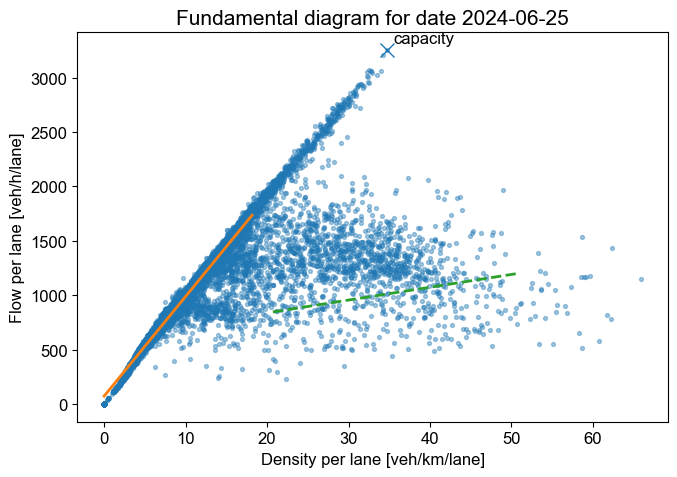


Per-lane FD summary per selected day:
2024-06-25 {'points': 15840, 'q_cap_veh_h_per_lane': 3255.0, 'k_cap_veh_km_per_lane': 34.67, 'v_at_cap_kmh': 93.9, 'vf_est_kmh': np.float64(91.6)}


In [6]:
DAYS = [1]                 # pick a day number from the printed day_table, e.g., 0 or [0, 2, 5]
LANES = 4                  
SPEED_FF = 80.0            # km/h: free-flow candidates
SPEED_CONG = 40.0          # km/h: congested candidates
ALPHA = 0.4                # scatter transparency

plt.rcParams.update({
    "font.family": "Arial",      # e.g., "serif", "sans-serif", "Times New Roman"
    "font.size": 14,             # base font size
    "axes.titlesize": 15,        # title font size
    "axes.labelsize": 12,        # x/y label size
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

def _load_fd_rows(day_idxs):
    out = []
    for d in ([day_idxs] if isinstance(day_idxs, int) else day_idxs):
        p = day_table.loc[d, "path"]
        date_str = day_table.loc[d, "date"]

        fw = parse_matrix(p, r"Gebruikte intensiteiten")   # veh/h (cross-section)
        sw = parse_matrix(p, r"Gebruikte snelheden")       # km/h (mean)
        f  = tidy(fw, "flow_veh_h")
        s  = tidy(sw, "speed_kmh")

        df = (f.merge(s, on=["time","km"], how="inner")
                .assign(density_veh_km=lambda d: d["flow_veh_h"]/d["speed_kmh"])   # cross-section density
                .assign(date=date_str))
        out.append(df)
    return pd.concat(out, ignore_index=True)

fd = _load_fd_rows(DAYS).dropna(subset=["flow_veh_h","speed_kmh","density_veh_km"])

fd = fd.assign(
    flow_per_lane      = fd["flow_veh_h"] / LANES,
    density_per_lane   = fd["density_veh_km"] / LANES
)

print("Loaded FD points:", fd.shape[0], "| days:", sorted(fd['date'].unique().tolist()))
print("Per-lane density [veh/km/lane]:", f"{fd['density_per_lane'].min():.2f} → {fd['density_per_lane'].max():.2f}")
print("Per-lane flow    [veh/h/lane]:", f"{fd['flow_per_lane'].min():.0f} → {fd['flow_per_lane'].max():.0f}")

def capacity_point(df, kcol="density_per_lane", qcol="flow_per_lane"):
    i = df[qcol].idxmax()
    return df.loc[i, [kcol, qcol, "speed_kmh"]].to_dict()

def fit_branch(df, x="density_per_lane", y="flow_per_lane"):
    """Simple OLS line fit y = a*x + b; returns a,b"""
    X = np.c_[np.ones(len(df)), df[x].to_numpy()]
    yv = df[y].to_numpy()
    a, b = np.linalg.lstsq(X, yv, rcond=None)[0]  # a=intercept, b=slope
    return a, b

fig, ax = plt.subplots(figsize=(7,5))
for day, dday in fd.groupby("date", sort=True):
    ax.scatter(dday["density_per_lane"], dday["flow_per_lane"], s=8, alpha=ALPHA, label=day)
    cap = capacity_point(dday)
    ax.plot(cap["density_per_lane"], cap["flow_per_lane"], marker="x", ms=10, color="tab:blue")
    ax.annotate("capacity", (cap["density_per_lane"], cap["flow_per_lane"]),
                xytext=(5,5), textcoords="offset points", fontsize=12)

    ff = dday[dday["speed_kmh"] >= SPEED_FF]
    if len(ff) > 10:
        a, b = fit_branch(ff)  # slope b ~ free-flow speed (km/h) if intercept ≈ 0
        xs = np.linspace(0, ff["density_per_lane"].quantile(0.95), 50)
        ax.plot(xs, a + b*xs, linewidth=2, color="tab:orange")

    cg = dday[dday["speed_kmh"] <= SPEED_CONG]
    if len(cg) > 10:
        a2, b2 = fit_branch(cg)
        xs = np.linspace(cg["density_per_lane"].quantile(0.05), cg["density_per_lane"].quantile(0.95), 50)
        ax.plot(xs, a2 + b2*xs, linewidth=2, linestyle="--", color="tab:green")

ax.set_xlabel("Density per lane [veh/km/lane]")
ax.set_ylabel("Flow per lane [veh/h/lane]")
ax.set_title(f"Fundamental diagram for date {day}")
for spine in ax.spines.values():
    spine.set_visible(True)
plt.tight_layout()
plt.show()

# Print a small summary per day 
def summarize_day(dday):
    cap = capacity_point(dday)
    ff = dday[dday["speed_kmh"] >= SPEED_FF]
    vf_est = np.nan
    if len(ff) > 10:
        a, b = fit_branch(ff)
        vf_est = b  
    return {
        "points": len(dday),
        "q_cap_veh_h_per_lane": round(cap["flow_per_lane"], 0),
        "k_cap_veh_km_per_lane": round(cap["density_per_lane"], 2),
        "v_at_cap_kmh"         : round(cap["speed_kmh"], 1),
        "vf_est_kmh"           : round(vf_est, 1) if np.isfinite(vf_est) else np.nan,
    }

print("\nPer-lane FD summary per selected day:")
for day, dday in fd.groupby("date", sort=True):
    print(day, summarize_day(dday))

# 4. Travel time analysis (10 min)
- Compute average travel times along the motorway stretch per time-of-day.
- Compare peak vs. off-peak and day-to-day variability.


Compute average travel times along the motorway stretch per time-of-day.

 Day 3 → Date 2024-06-27


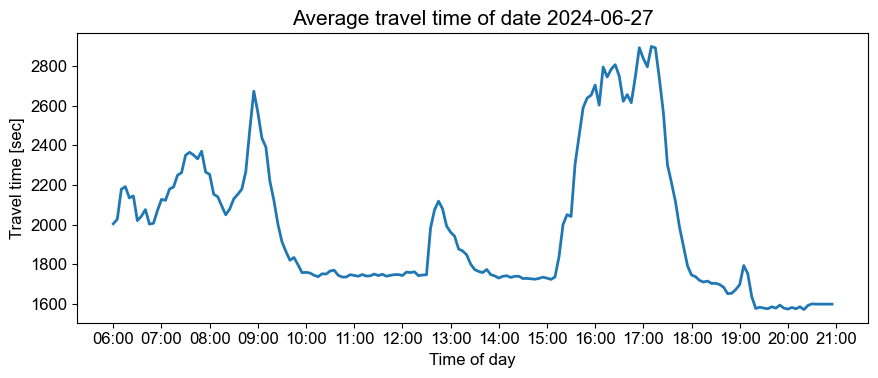

In [7]:
DAY = 3               # pick a day number from the printed day_table, e.g., 0 or [0, 2, 5]
METHOD_COL = "m3_avg" 

fpath = day_table.loc[DAY, "path"]
date  = day_table.loc[DAY, "date"]
tt    = parse_travel_times(fpath)

keep = [c for c in ["time","ref_avg","m1_avg","m2_avg","m3_avg"] if c in tt.columns]
tt   = tt[keep].dropna(subset=[METHOD_COL]).copy()
tt["tod"] = tt["time"].dt.floor("5min")
per_tod   = tt.groupby("tod", as_index=False)[METHOD_COL].mean()
per_tod.rename(columns={METHOD_COL:"tt_sec"}, inplace=True)
print(f" Day {DAY} → Date {date}")

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(per_tod["tod"], per_tod["tt_sec"], lw=2)
start = per_tod["tod"].iloc[0].replace(hour=6, minute=0)
end   = per_tod["tod"].iloc[0].replace(hour=21, minute=0)
ticks = pd.date_range(start=start, end=end, freq="1h")  # every 1h, you can change
ax.set_xticks(ticks)
ax.set_xticklabels([t.strftime("%H:%M") for t in ticks], rotation=0)
ax.set_title(f"Average travel time of date {date}")
ax.set_xlabel("Time of day")
ax.set_ylabel("Travel time [sec]")

for spine in ax.spines.values():
    spine.set_visible(True)

plt.tight_layout()
plt.show()

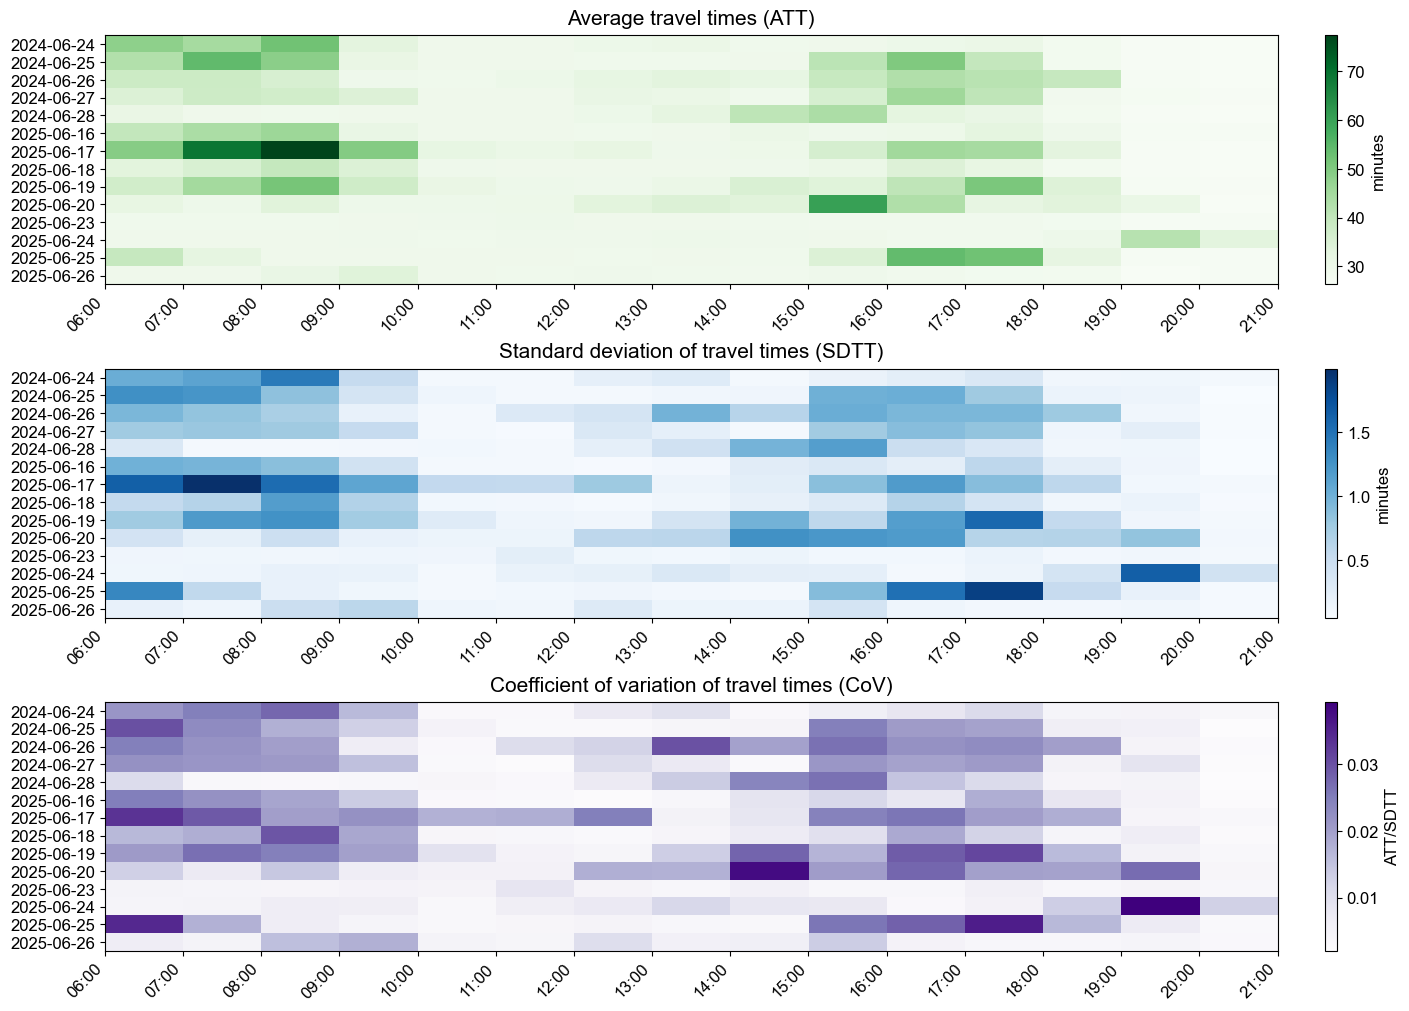

In [9]:
DAYS = "all"
METHOD_COL = "m3_avg"

def _select_days(sel):
    if sel == "all":
        return list(range(len(day_table)))
    if isinstance(sel, int):
        return [sel]
    return list(sel)

def load_tt(selected):
    frames = []
    for d in _select_days(selected):
        f  = day_table.loc[d, "path"]
        tt = parse_travel_times(f)
        keep = [c for c in ["time","m3_avg","m3_sd"] if c in tt.columns]
        frames.append(tt[keep].assign(day_idx=d))
    return pd.concat(frames, ignore_index=True)


tt_all = load_tt(DAYS)
tt = tt_all[["time","m3_avg","m3_sd"]].copy()
tt["date"] = tt["time"].dt.date
tt["hour"] = tt["time"].dt.hour
tt = tt[tt["hour"].between(6, 20)]

dates = sorted(tt["date"].unique())
tt["date"] = pd.Categorical(tt["date"], categories=dates, ordered=True)

ATT  = (tt.pivot_table(index="date", columns="hour", values="m3_avg",
                       aggfunc="mean", observed=False) / 60.0).reindex(dates)
SDTT = (tt.pivot_table(index="date", columns="hour", values="m3_sd",
                       aggfunc="mean", observed=False) / 60.0).reindex(dates)
CoV = SDTT.divide(ATT.where(ATT > 0))

def cmap_with_bad(name):
    return mpl_cmaps.get_cmap(name).with_extremes(bad="#f0f0f0")

def heatmap_hours(ax, data: pd.DataFrame, title: str, cbar_label: str, cmap="viridis"):
    hours = np.sort(data.columns.astype(int))
    data  = data.reindex(columns=hours)
    nrows, ncols = data.shape
    h0, hN = hours[0], hours[-1]

    im = ax.imshow(
        data.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        extent=(h0, hN + 1, nrows - 0.5, -0.5)  # map each hour to [h, h+1)
    )

    ax.set_yticks(np.arange(nrows))
    ax.set_yticklabels([str(d) for d in data.index])

    ax.set_xticks(np.r_[hours, hN + 1])
    ax.set_xticklabels([f"{h:02d}:00" for h in hours] + [f"{hN+1:02d}:00"], rotation=45, ha="right")
    ax.set_xlim(h0, hN + 1)

    ax.set_title(title, pad=8)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)
heatmap_hours(axes[0], ATT,  "Average travel times (ATT)",               "minutes", cmap="Greens")
heatmap_hours(axes[1], SDTT, "Standard deviation of travel times (SDTT)", "minutes", cmap="Blues")
heatmap_hours(axes[2], CoV,  "Coefficient of variation of travel times (CoV)", "ATT/SDTT", cmap=cmap_with_bad("Purples"))

plt.show()


# 5. Speed-contour plots (~10 min)
- Generate contour plots using notebook templates.
- Identify congestion patterns and anomalies.
- Compare days with and without incidents.


Selected date [0] 2024-06-24


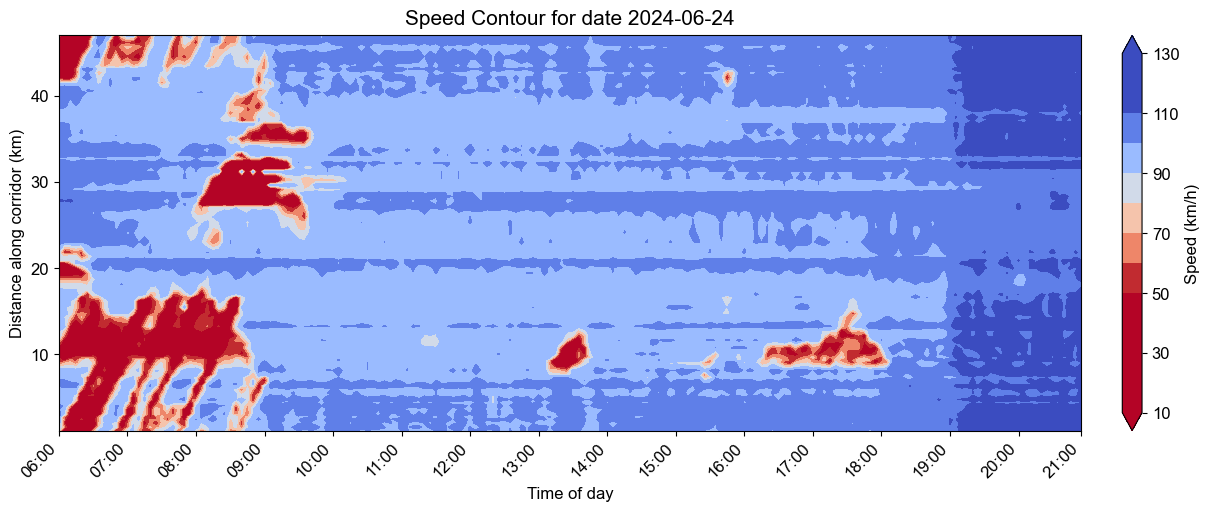

In [10]:
# ===================
# Speed Contour Plots
# ===================

DAYS = [0]              # choose days by index from `day_table`, e.g. [0], [2], [3]
TIME_START, TIME_END = "06:00", "20:59"
SPEED_CMAP = "coolwarm_r"  
N_LEVELS = 14           # number of contour levels

def load_speed_for_day(day_idx: int) -> pd.DataFrame:
    """
    Parse 'Gebruikte snelheden' from the file at day_table[day_idx].
    Returns long-form df with columns: time, km, speed_kmh
    """
    p = day_table.loc[day_idx, "path"]
    wide = parse_matrix(p, r"Gebruikte\s+snelheden")  # (km/h)
    spd = tidy(wide, "speed_kmh")[["time", "km", "speed_kmh"]]
    spd["time"] = pd.to_datetime(spd["time"])
    spd["km"] = spd["km"].astype(float)
    spd["speed_kmh"] = spd["speed_kmh"].astype(float)
    return spd

def build_speed_grid(speed_df: pd.DataFrame):
    """
    Pivot to a grid: rows=time (5-min), cols=km, values=speed_kmh.
    Restrict to TIME_START..TIME_END.
    """
    Z = (speed_df
         .pivot_table(index="time", columns="km", values="speed_kmh", aggfunc="mean")
         .sort_index())
    Z = Z.between_time(TIME_START, TIME_END)
    km_vals = Z.columns.to_numpy(float)   
    t_vals  = Z.index                     
    return Z, km_vals, t_vals

def hour_ticks(t_index: pd.DatetimeIndex):
    """
    Hourly ticks at :00 (06..20) using integer x positions,
    plus a right-edge '21:00' label (no extra data plotted).
    """
    mask = (t_index.minute == 0) & (t_index.hour >= 6) & (t_index.hour <= 20)
    pos  = np.where(mask)[0].tolist()
    labs = [f"{h:02d}:00" for h in t_index[mask].hour.tolist()]
    pos.append(len(t_index) - 1)  
    labs.append("21:00")
    return pos, labs

def plot_speed_contour(Z: pd.DataFrame, km_vals: np.ndarray, t_vals: pd.DatetimeIndex, title: str):
    """
    Filled contour: x=time (index positions), y=km, z=speed(km/h).
    """
    V = Z.to_numpy()            
    Vt = V.T                   

    vmin, vmax = np.nanpercentile(V, 5), np.nanpercentile(V, 95)
    x = np.arange(V.shape[0])   
    y = km_vals                
    X, Y = np.meshgrid(x, y)   
    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)
    CS = ax.contourf(X, Y, Vt, levels=N_LEVELS, cmap=SPEED_CMAP,
                     vmin=vmin, vmax=vmax, extend="both")
    
    cb = plt.colorbar(CS, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Speed (km/h)")
    ax.set_ylabel("Distance along corridor (km)")
    xt, xl = hour_ticks(t_vals)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")
    ax.set_title(title, pad=8)
    plt.show()

chosen = []
for i in DAYS:
    if (i < 0) or (i >= len(day_table)):
        print(f"Skip index {i}: out of range (0..{len(day_table)-1}).")
        continue
    date_i = day_table.loc[i, "date"]
    chosen.append((i, date_i))
    print(f"\nSelected date [{i}] {date_i}")

    spd = load_speed_for_day(i)
    if spd.empty:
        print(f"No speed data for day index {i} ({date_i}).")
        continue
    Z, km_vals, t_vals = build_speed_grid(spd)
    plot_speed_contour(Z, km_vals, t_vals, title=f"Speed Contour for date {date_i}")

if not chosen:
    print("No valid DAYS selected.")

Available dates: [datetime.date(2024, 6, 27)]


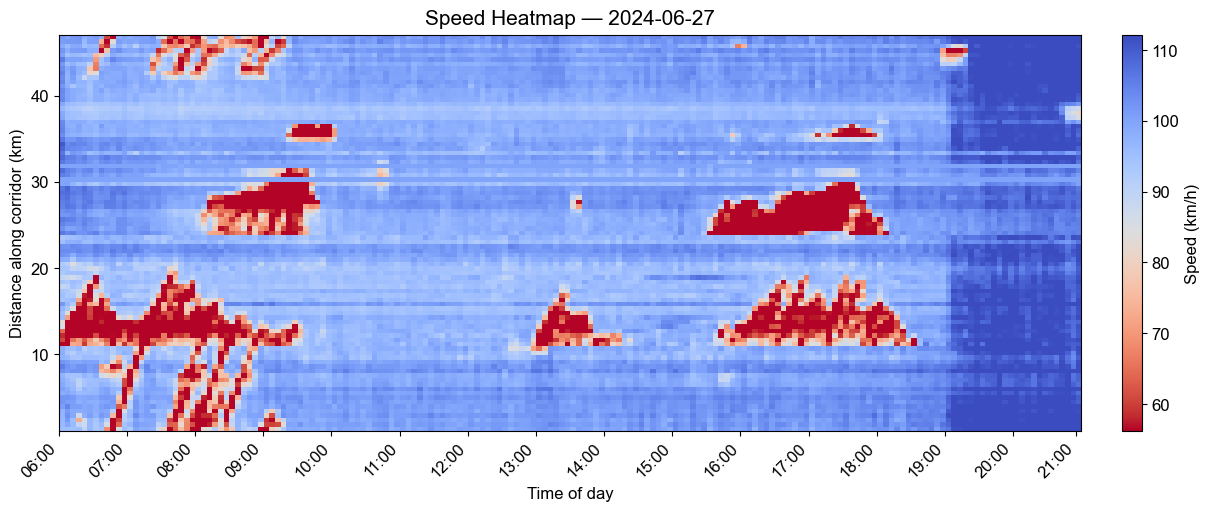

In [45]:
# Without contours (Optional)

DAYS = [0]          # indices into the sorted list of dates (e.g. [0], [1,2])
SPEED_CMAP = "coolwarm_r"

speed = speed.copy()
speed["date"] = speed["time"].dt.date

dates_all = np.array(sorted(speed["date"].unique()))
print("Available dates:", dates_all)

def build_speed_grid_for_date(date):
    """Return a pivot table: rows=time, cols=km, values=speed_kmh, restricted to 06:00–20:59."""
    df = speed.loc[speed["date"] == date, ["time","km","speed_kmh"]].copy()
    if df.empty:
        return None, None, None

    Z = df.pivot_table(index="time", columns="km", values="speed_kmh", aggfunc="mean").sort_index()
    Z = Z.between_time("06:00", "20:59")  # keep daytime
    return Z, Z.columns.to_numpy(float), Z.index

def hour_ticks(t_index):
    """Build xticks at hourly marks (06:00..20:00) + add 21:00 at right edge."""
    mask = (t_index.minute == 0) & (t_index.hour >= 6) & (t_index.hour <= 20)
    pos  = np.where(mask)[0].tolist()
    labs = [f"{h:02d}:00" for h in t_index[mask].hour.tolist()]
    pos.append(len(t_index) - 1)
    labs.append("21:00")
    return pos, labs

def plot_speed_heatmap(Z, km_vals, t_vals, title, cmap=SPEED_CMAP):
    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)

    V = Z.to_numpy()  
    vmin, vmax = np.nanpercentile(V, 5), np.nanpercentile(V, 95)

    im = ax.imshow(V.T, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax,
                   origin="lower", extent=[0, V.shape[0], km_vals.min(), km_vals.max()])
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Speed (km/h)")
    ax.set_ylabel("Distance along corridor (km)")
    xt, xl = hour_ticks(t_vals)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")

    ax.set_title(title, pad=8)
    plt.show()

for i in DAYS:
    if i < 0 or i >= len(dates_all):
        print(f"Skip index {i}: out of range.")
        continue
    date_i = dates_all[i]
    Z, km_vals, t_vals = build_speed_grid_for_date(date_i)
    if Z is None:
        print(f"No speed data for {date_i}")
        continue
    plot_speed_heatmap(Z, km_vals, t_vals, title=f"Speed Heatmap — {date_i}")



Selected date [1] 2024-06-25


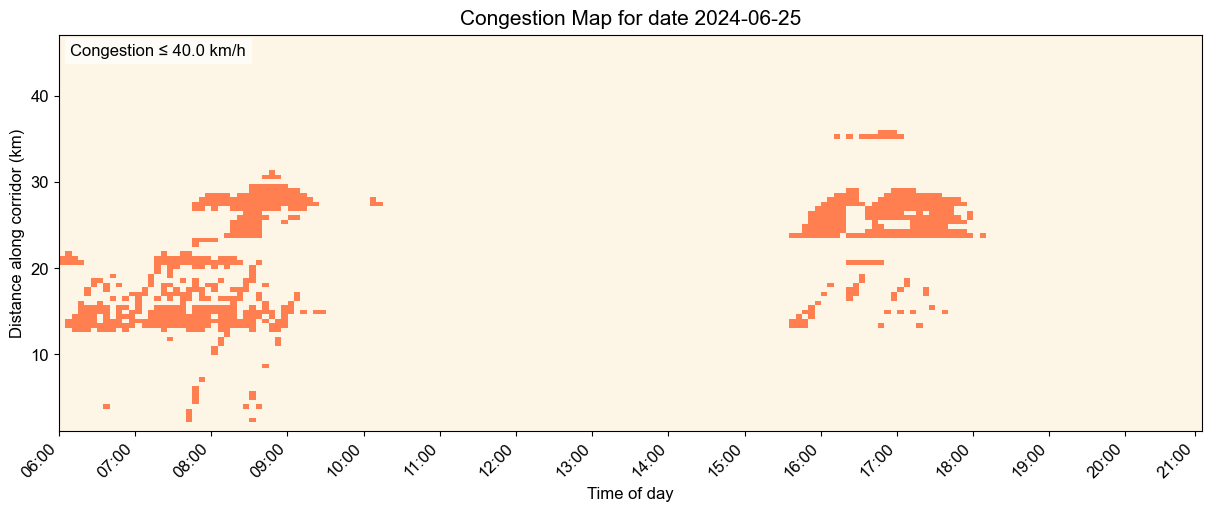

In [17]:
# ===============================
# Highlight Congestion Areas Only
# ===============================

DAYS = [1]              # choose days by index from `day_table`, e.g. [0], [2], [3]         
ABS_THRESHOLD = 40.0    # absolute threshold [km/h], or None
REL_QUANTILE = 0.25     # if abs is None, use relative (lowest 25%)

def congestion_mask(Z, abs_thr=None, quantile=None):
    V = Z.to_numpy()
    if abs_thr is not None:
        thr = abs_thr
    elif quantile is not None:
        thr = np.nanquantile(V, quantile)
    else:
        raise ValueError("Must set abs_thr or quantile")
    return (V <= thr), thr

def plot_congestion_only(Z, km_vals, t_vals, title,
                         abs_thr=ABS_THRESHOLD,
                         rel_q=REL_QUANTILE,
                         cong_color="coral", neutral_color="oldlace"):
    """
    Show congestion cells filled with one color; non-congested cells as neutral.
    """
    V = Z.to_numpy()
    cong, thr = (congestion_mask(Z, abs_thr=abs_thr)
                 if abs_thr is not None else
                 congestion_mask(Z, quantile=rel_q))

    mask = cong.astype(int).T   
    x = np.arange(V.shape[0]) 
    y = km_vals
    X, Y = np.meshgrid(x, y)
    fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)
    cmap = ListedColormap([neutral_color, cong_color])
    im = ax.imshow(mask, aspect="auto", origin="lower", cmap=cmap,
                   extent=[0, V.shape[0], km_vals.min(), km_vals.max()])

    ax.set_ylabel("Distance along corridor (km)")
    xt, xl = hour_ticks(t_vals)
    ax.set_xticks(xt)
    ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_xlabel("Time of day")

    ax.set_title(title, pad=8)
    ax.text(0.01, 0.98, f"Congestion ≤ {thr:.1f} km/h",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=12, bbox=dict(facecolor="white", alpha=0.7, lw=0))
    plt.show()

for i in DAYS:
    if (i < 0) or (i >= len(day_table)):
        print(f"Skip index {i}: out of range (0..{len(day_table)-1}).")
        continue
    date_i = day_table.loc[i, "date"]
    print(f"\nSelected date [{i}] {date_i}")

    spd = load_speed_for_day(i)
    if spd.empty:
        print(f"No speed data for {date_i}")
        continue
    Z, km_vals, t_vals = build_speed_grid(spd)
    plot_congestion_only(Z, km_vals, t_vals,
                         title=f"Congestion Map for date {date_i}")

# 6. Shockwave theory (~10 min)
- Use contour plots to estimate propagation speed of congestion fronts.


Selected date [4] 2024-06-28

Front estimates at Threshold=40.0 km/h within KM_range=(0.0, 15.0):
  15:40: km ≈ 6.50
  16:10: km ≈ 2.70
  Δx = -3.800 km,  Δt = 30.00 min  →  w = -7.60 km/h  (upstream (against traffic))


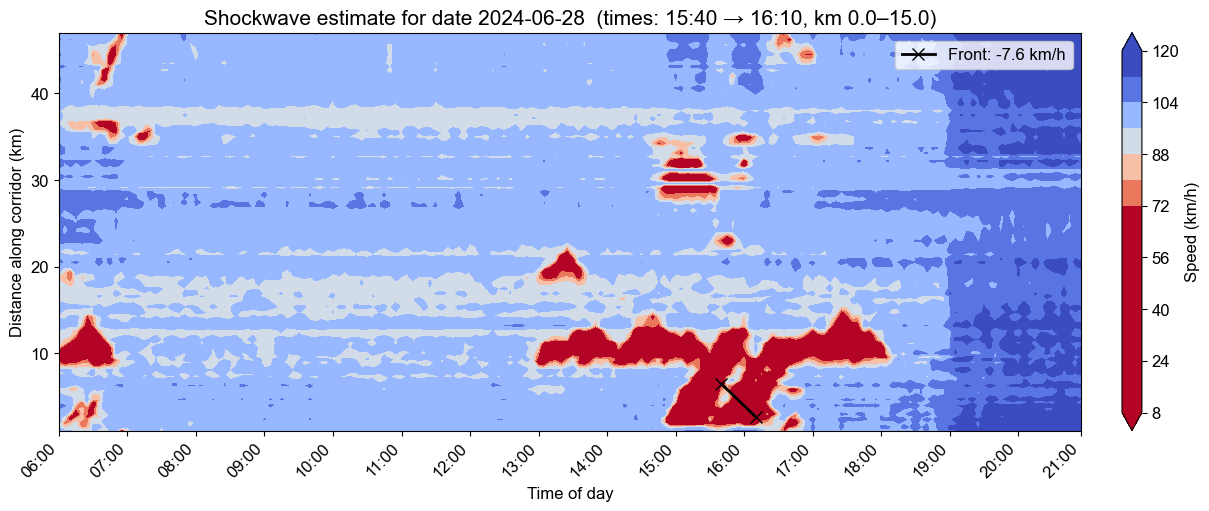

In [46]:
DAY        = 4            # pick a day index from day_table
THRESHOLD  = 40.0         # km/h: defines the congestion front
TIME_A     = "15:40"      # first time-of-day (HH:MM) within 06:00–20:59
TIME_B     = "16:10"      # second time-of-day
KM_RANGE   = (0.0, 15.0)  # restrict search to km between [km_min, km_max]
N_LEVELS   = 14
CMAP       = "coolwarm_r"

if (DAY < 0) or (DAY >= len(day_table)):
    raise IndexError(f"DAY={DAY} out of range (0..{len(day_table)-1}).")

date_i = day_table.loc[DAY, "date"]
print(f"Selected date [{DAY}] {date_i}")

spd = load_speed_for_day(DAY)
Z, km_vals, t_vals = build_speed_grid(spd)       # Z: (T, K)
V = Z.to_numpy()
T, K = V.shape

def time_to_index(t_vals: pd.DatetimeIndex, hhmm: str) -> int:
    target = pd.Timestamp(f"{t_vals[0].date()} {hhmm}")
    if target < t_vals[0]:  target = t_vals[0]
    if target > t_vals[-1]: target = t_vals[-1]
    return int(np.argmin(np.abs((t_vals - target).total_seconds())))

def front_km_at_time(V_col_km: np.ndarray, km_vals: np.ndarray,
                     thr: float, km_range: tuple[float,float] | None = None) -> float | None:
    """
    Given speeds along km at one time (shape K,), return km where speed ≈ thr.
    Restrict search to [km_min, km_max] if provided.
    """
    sp, kms = V_col_km.copy(), km_vals.copy()

    if km_range is not None:
        km_min, km_max = km_range
        mask = (kms >= km_min) & (kms <= km_max)
        if not mask.any():
            return None
        sp, kms = sp[mask], kms[mask]

    if len(kms) == 0 or np.all(np.isnan(sp)):
        return None

    idx = int(np.nanargmin(np.abs(sp - thr)))
    return float(kms[idx])

ia = time_to_index(t_vals, TIME_A)
ib = time_to_index(t_vals, TIME_B)
kma = front_km_at_time(V[ia, :], km_vals, THRESHOLD, km_range=KM_RANGE)
kmb = front_km_at_time(V[ib, :], km_vals, THRESHOLD, km_range=KM_RANGE)

if kma is None or kmb is None:
    raise RuntimeError("Could not locate the congestion front at one of the times. "
                       "Try a different THRESHOLD, times, or KM_RANGE.")

dt_min = (t_vals[ib] - t_vals[ia]).total_seconds() / 60.0
dx_km  = kmb - kma
w_kmh  = (dx_km / dt_min) * 60.0
direction = "upstream (against traffic)" if w_kmh < 0 else "downstream (with traffic)"

print(f"\nFront estimates at Threshold={THRESHOLD:.1f} km/h within KM_range={KM_RANGE}:")
print(f"  {TIME_A}: km ≈ {kma:.2f}")
print(f"  {TIME_B}: km ≈ {kmb:.2f}")
print(f"  Δx = {dx_km:.3f} km,  Δt = {dt_min:.2f} min  →  w = {w_kmh:.2f} km/h  ({direction})")

x = np.arange(T)             
y = km_vals                  
X, Y = np.meshgrid(x, y)
vmin, vmax = np.nanpercentile(V, 5), np.nanpercentile(V, 95)

fig, ax = plt.subplots(1, 1, figsize=(12, 5), constrained_layout=True)
CS = ax.contourf(X, Y, V.T, levels=N_LEVELS, cmap=CMAP, vmin=vmin, vmax=vmax, extend="both")
cb = plt.colorbar(CS, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("Speed (km/h)")

ax.plot([ia, ib], [kma, kmb], "kx-", lw=2, ms=8, label=f"Front: {w_kmh:.1f} km/h")
ax.legend(loc="upper right")
ax.set_ylabel("Distance along corridor (km)")
xt, xl = hour_ticks(t_vals)
ax.set_xticks(xt)
ax.set_xticklabels(xl, rotation=45, ha="right")
ax.set_xlabel("Time of day")
ax.set_title(f"Shockwave estimate for date {date_i}  (times: {TIME_A} → {TIME_B}, km {KM_RANGE[0]}–{KM_RANGE[1]})")

plt.show()

# 7. Sensor correlation analysis (~10 min)
- Compute correlations between consecutive sensors.
- Explore lead/lag relationships to see how congestion propagates.
- Relate to the concept of information flow.

Selected [1] 2024-06-25 — feature: speed
First rows:
   km_from  km_to      corr  n_pairs
0      1.1    1.5  0.894723      180
1      1.5    2.0  0.975685      180
2      2.0    2.4  0.944849      180
3      2.4    2.7  0.947305      180
4      2.7    3.0  0.915377      180
5      3.0    3.6  0.957360      180
6      3.6    4.0  0.969710      180
7      4.0    4.4  0.924277      180
8      4.4    4.7  0.937158      180
9      4.7    5.2  0.943442      180


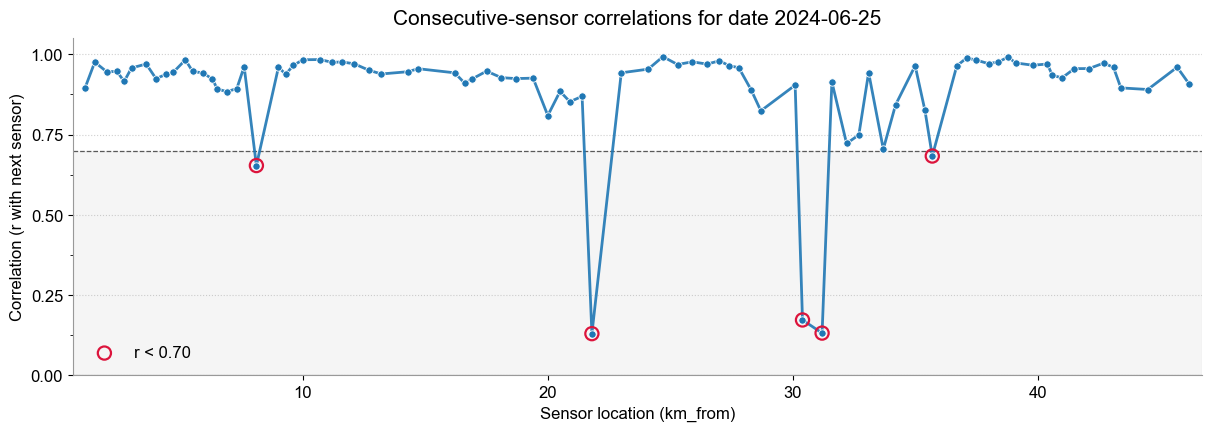

In [ ]:
# =================================
# Sensor Agreement Along a Corridor
# =================================

DAY = 1                          # pick a date from day_table
FEATURE = "speed"                # toggle feature: "speed" | "flow"
TIME_START, TIME_END = "06:00", "20:59"
ROLL_MINUTES = None              # e.g. 15 for a 15-min rolling mean; or None
PRINT_HEAD = 10
MIN_OVERLAP = 6                  # require at least N overlapping points for a pair; set 0 to disable
ALERT_CUTOFF = 0.70              # highlight low-agreement segments in visuals

def load_feature_for_day(day_idx: int, feature: str) -> pd.DataFrame:
    """
    Returns tidy long-form df with columns: time, km, metric
    feature in {"speed","flow","occupancy"}.
    """
    p = day_table.loc[day_idx, "path"]

    if feature == "speed":
        wide = parse_matrix(p, r"Gebruikte\s+snelheden") 
        df = tidy(wide, "value")[["time","km","value"]]
        df = df.rename(columns={"value":"metric"})
        unit = "km/h"

    elif feature == "flow":
        wide = parse_matrix(p, r"Gebruikte\s+intensiteiten")    
        df = tidy(wide, "value")[["time","km","value"]]
        df = df.rename(columns={"value":"metric"})
        unit = "veh/h"

    else:
        raise ValueError("FEATURE must be one of: 'speed' or 'flow'.")

    df["time"] = pd.to_datetime(df["time"])
    df["km"] = df["km"].astype(float)
    df["metric"] = pd.to_numeric(df["metric"], errors="coerce")
    df.attrs["unit"] = unit
    return df

def build_grid(df_long: pd.DataFrame) -> tuple[pd.DataFrame, np.ndarray, pd.DatetimeIndex, str]:
    """
    Pivot to a grid: rows=time (5-min), cols=km, values=metric.
    Restrict to TIME_START..TIME_END. Optionally smooth.
    """
    Z = (df_long
         .pivot_table(index="time", columns="km", values="metric", aggfunc="mean")
         .sort_index())
    Z = Z.between_time(TIME_START, TIME_END)

    if ROLL_MINUTES:
        if len(Z.index) >= 2:
            step_min = int((Z.index[1] - Z.index[0]).total_seconds() // 60)
        else:
            step_min = 5
        w = max(1, int(round(ROLL_MINUTES / step_min)))
        Z = Z.rolling(window=w, min_periods=max(1, w//2), center=True).mean()

    km_vals = Z.columns.to_numpy(float)
    t_vals  = Z.index
    unit    = df_long.attrs.get("unit", "")
    return Z, km_vals, t_vals, unit

def _pearson(x: np.ndarray, y: np.ndarray) -> tuple[float, int]:
    """
    Pearson r that returns NaN if <3 points overlap or zero variance.
    Returns (r, n_overlap).
    """
    m = ~np.isnan(x) & ~np.isnan(y)
    n = int(m.sum())
    if n < 3:
        return np.nan, n
    xv, yv = x[m].astype(float), y[m].astype(float)
    dx, dy = xv - xv.mean(), yv - yv.mean()
    num = np.sum(dx * dy)
    den = np.sqrt(np.sum(dx * dx) * np.sum(dy * dy))
    if den == 0.0:
        return np.nan, n
    return float(num / den), n

def consecutive_correlations(Z: pd.DataFrame) -> pd.DataFrame:
    """
    Pearson correlations between consecutive sensor columns (km_j, km_{j+1}),
    robust to NaNs and zero-variance series. Also returns n_pairs used.
    """
    V = Z.to_numpy()                          # (T, K)
    kms = Z.columns.to_numpy(float)
    corrs, n_pairs = [], []
    for j in range(len(kms) - 1):
        r, n = _pearson(V[:, j], V[:, j+1])
        corrs.append(r)
        n_pairs.append(n)
    out = pd.DataFrame({"km_from": kms[:-1], "km_to": kms[1:], "corr": corrs, "n_pairs": n_pairs})
    if MIN_OVERLAP and MIN_OVERLAP > 0:
        out.loc[out["n_pairs"] < MIN_OVERLAP, "corr"] = np.nan
    return out

def plot_corr_corridor(corr_df, title):
    CMAP = "RdYlBu_r"
    VMIN, VMAX = -1.0, 1.0

    segs, colors = [], []
    for _, r in corr_df.dropna(subset=["corr"]).iterrows():
        segs.append([(r["km_from"], 0.0), (r["km_to"], 0.0)])
        colors.append(r["corr"])

    fig, ax = plt.subplots(1, 1, figsize=(12, 2.6), constrained_layout=True)
    if segs:
        lc = LineCollection(segs, cmap=CMAP, norm=Normalize(VMIN, VMAX), linewidths=10)
        lc.set_array(np.array(colors))
        ax.add_collection(lc)
        cbar = plt.colorbar(lc, ax=ax, fraction=0.046, pad=0.08)
        cbar.set_label("Pearson r")
    else:
        ax.text(0.5, 0.5, "No valid segment correlations", ha="center", va="center", transform=ax.transAxes)

    low = corr_df["corr"] < ALERT_CUTOFF
    if low.any():
        xs = 0.5 * (corr_df.loc[low, "km_from"].to_numpy() + corr_df.loc[low, "km_to"].to_numpy())
        ax.plot(xs, np.zeros_like(xs), "v", ms=7, color="black", label=f"corr<{ALERT_CUTOFF:.2f}")

    ax.set_xlim(corr_df["km_from"].min(), corr_df["km_to"].max())
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_xlabel("Distance along corridor (km)")
    ax.set_title(title)
    if low.any():
        ax.legend(loc="upper right", frameon=True)
    plt.show()

def plot_corr_lollipop(corr_df, title):
    CMAP = "RdYlBu_r"
    VMIN, VMAX = -1.0, 1.0

    df = corr_df.copy().reset_index(drop=True)
    x = df["km_from"].to_numpy()
    y = df["corr"].to_numpy()

    fig, ax = plt.subplots(1, 1, figsize=(12, 4), constrained_layout=True)
    for xi, yi in zip(x, y):
        if np.isnan(yi): continue
        ax.plot([xi, xi], [0, yi], lw=2, color="0.85")
    sc = ax.scatter(x[~np.isnan(y)], y[~np.isnan(y)], c=y[~np.isnan(y)],
                    cmap=CMAP, vmin=VMIN, vmax=VMAX, s=60, zorder=3, edgecolor="k", linewidth=0.5)

    idx_low = np.where((~np.isnan(y)) & (y < ALERT_CUTOFF))[0]
    if idx_low.size > 0:
        ax.scatter(x[idx_low], y[idx_low], facecolors="none", edgecolors="k", s=180, linewidths=1.5, zorder=4)
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(ALERT_CUTOFF, color="tab:gray", lw=0.8, ls="--")
    ax.set_ylim(-1.05, 1.05)
    ax.set_xlabel("Sensor location (km_from)")
    ax.set_ylabel("Correlation with next sensor")
    ax.set_title(title)
    cbar = plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Pearson r")
    plt.show()

if (DAY < 0) or (DAY >= len(day_table)):
    raise IndexError(f"DAY={DAY} out of range (0..{len(day_table)-1}).")

date_i = day_table.loc[DAY, "date"]
print(f"Selected [{DAY}] {date_i} — feature: {FEATURE}")

feat_df = load_feature_for_day(DAY, FEATURE)
Z, km_vals, t_vals, unit = build_grid(feat_df)

corr_df = consecutive_correlations(Z)
print("First rows:")
print(corr_df.head(PRINT_HEAD))

df = corr_df.copy().dropna(subset=["corr"]).reset_index(drop=True)
x = df["km_from"].to_numpy()
y = df["corr"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 4.2), constrained_layout=True)
ax.axhspan(-1.0, ALERT_CUTOFF, color="0.85", alpha=0.25, zorder=0)
ax.axhline(0, color="0.25", lw=0.8, zorder=1)
ax.axhline(ALERT_CUTOFF, color="0.35", lw=0.9, ls="--", zorder=1)
ax.plot(x, y, lw=2.0, color="C0", alpha=0.9, zorder=2)
ax.scatter(x, y, s=28, color="C0", edgecolor="white", linewidth=0.6, zorder=3)

low = y < ALERT_CUTOFF
if np.any(low):
    ax.scatter(x[low], y[low], s=90, facecolors="none", edgecolors="crimson",
               linewidths=1.6, zorder=4, label=f"r < {ALERT_CUTOFF:.2f}")

ax.set_title(f"Consecutive-sensor correlations for date {date_i}", pad=10)
ax.set_xlabel("Sensor location (km_from)")
ax.set_ylabel("Correlation (r with next sensor)")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_locator(MultipleLocator(0.25))
ax.yaxis.set_minor_locator(MultipleLocator(0.125))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))

ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
for spine in ("left", "bottom"):
    ax.spines[spine].set_color("0.6")
ax.grid(True, which="major", axis="y", linestyle=":", linewidth=0.8, alpha=0.6)

if np.any(low):
    ax.legend(frameon=False, loc="lower left")

plt.show()


Selected [1] 2024-06-25 — feature: speed
Lead/lag summary (first rows):
   km_from  km_to  dx_km  best_lag_min  r_at_lag  prop_speed_kmh
0      1.1    1.5    0.4      1.457247  0.894723       16.469414
1      1.5    2.0    0.5      0.456821  0.975685        0.000000
2      2.0    2.4    0.4      0.556843  0.944849        0.000000
3      2.4    2.7    0.3      0.885165  0.947305        0.000000
4      2.7    3.0    0.3      1.269248  0.915377       14.181625
5      3.0    3.6    0.6      0.501783  0.957360        0.000000


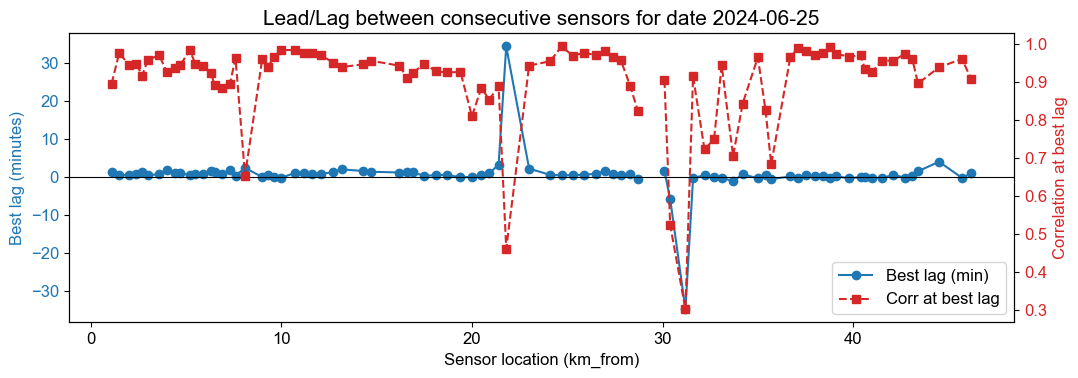

In [ ]:
# ===================================================
# Cross-Correlation Analysis — Lead/Lag & Propagation
# ===================================================

DAY = 1                    # pick a date from day_table
FEATURE = "speed"          # "speed" | "flow" | "occupancy"
TIME_START, TIME_END = "06:00", "20:59"  # window within the day
MAX_LAG_MIN   = 60         # search window for lag (+/- minutes)
MIN_OVERLAP   = 10         # min overlapping samples per lag
MIN_R_AT_LAG  = 0.15       # discard best lags with weak correlation
PAIR_INDEX    = 5          # pair to show detailed CCF for (0 = first pair)
TINY_LAG_FRACTION = 0.25   # treat |lag| < 0.25 * dt as synchronous -> speed 0

date_i = day_table.loc[DAY, "date"]
print(f"Selected [{DAY}] {date_i} — feature: {FEATURE}")

feat_df = load_feature_for_day(DAY, FEATURE)
Z, km_vals, t_vals, unit = build_grid(feat_df)   # Z: (T,K)

if len(t_vals) < 2:
    raise RuntimeError("Not enough time points to compute cross-correlation.")

dt_min = (t_vals[1] - t_vals[0]).total_seconds() / 60.0
max_lag_steps = int(np.floor(MAX_LAG_MIN / dt_min))

def xcorr_curve(x: np.ndarray, y: np.ndarray, max_lag_steps: int, min_overlap: int):
    """
    Return (lags_steps, r_at_lag) for lags in [-L..+L], where positive lag
    means x leads y by 'lag' steps. NaNs handled; lags with too little overlap
    or zero variance are set to NaN.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    L = max_lag_steps
    lags = np.arange(-L, L+1, dtype=int)
    rvals = np.full_like(lags, np.nan, dtype=float)

    for idx, lag in enumerate(lags):
        if lag >= 0:
            xs = x[:len(x) - lag]
            ys = y[lag:]
        else:
            xs = x[-lag:]
            ys = y[:len(y) + lag]

        m = ~np.isnan(xs) & ~np.isnan(ys)
        if m.sum() < min_overlap:
            continue

        xv = xs[m]; yv = ys[m]
        dx = xv - xv.mean(); dy = yv - yv.mean()
        denom = np.sqrt((dx*dx).sum() * (dy*dy).sum())
        if denom == 0.0:
            continue

        rvals[idx] = (dx*dy).sum() / denom

    return lags, rvals

def best_lag_from_curve_subsample(lags_steps: np.ndarray, rvals: np.ndarray) -> tuple[float, float]:
    """
    Quadratic interpolation around the discrete max to get a fractional lag.
    Returns (lag_steps_float, r_at_lag). Falls back to discrete if neighbors invalid.
    """
    if np.all(np.isnan(rvals)):
        return np.nan, np.nan
    i = int(np.nanargmax(rvals))
    r0 = rvals[i]; lag0 = float(lags_steps[i])

    if 0 < i < len(rvals)-1 and np.isfinite(rvals[i-1]) and np.isfinite(rvals[i+1]):
        rm, rp = rvals[i-1], rvals[i+1]
        denom = (rm - 2*r0 + rp)
        if denom != 0:
            delta = 0.5 * (rm - rp) / denom   # fractional offset in steps
            return lag0 + float(delta), float(r0)

    return lag0, float(r0)

V = Z.to_numpy()
rows = []
for j in range(len(km_vals) - 1):
    lags_s, r_lag = xcorr_curve(V[:, j], V[:, j+1], max_lag_steps, MIN_OVERLAP)
    lag_steps_f, rmax = best_lag_from_curve_subsample(lags_s, r_lag)

    if np.isnan(lag_steps_f) or (rmax < MIN_R_AT_LAG):
        lag_min = np.nan
        speed_kmh = np.nan
    else:
        lag_min = lag_steps_f * dt_min
        dx_km = float(km_vals[j+1] - km_vals[j])
        if abs(lag_min) < TINY_LAG_FRACTION * dt_min:
            speed_kmh = 0.0
        else:
            speed_kmh = dx_km / (lag_min / 60.0)

    rows.append({
        "km_from": km_vals[j],
        "km_to":   km_vals[j+1],
        "dx_km":   float(km_vals[j+1] - km_vals[j]),
        "best_lag_min": lag_min,
        "r_at_lag": rmax,
        "prop_speed_kmh": speed_kmh
    })

lag_df = pd.DataFrame(rows)
print("Lead/lag summary (first rows):")
print(lag_df.head(6))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(lag_df["km_from"], lag_df["best_lag_min"], "o-", color="tab:blue", label="Best lag (min)")
ax1.axhline(0, color="k", lw=0.8)
ax1.set_xlabel("Sensor location (km_from)")
ax1.set_ylabel("Best lag (minutes)", color="tab:blue")
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_title(f"Lead/Lag between consecutive sensors for date {date_i}")

ax2 = ax1.twinx()
ax2.plot(lag_df["km_from"], lag_df["r_at_lag"], "s--", color="tab:red", label="Corr at best lag")
ax2.set_ylabel("Correlation at best lag", color="tab:red")
ax2.tick_params(axis='y', labelcolor='tab:red')

h1,l1 = ax1.get_legend_handles_labels()
h2,l2 = ax2.get_legend_handles_labels()
ax2.legend(h1+h2, l1+l2, loc="lower right")
plt.tight_layout()
plt.show()


# 8. Incident integration (~10 min)
- Overlay incident data on contour plots.
- Compare incident characteristics with observed traffic effects.
- Discuss detection possibilities using only sensor data.


Note: We need incident data for this.